# Finding the snake first: does cropping help?

A photo of a snake is often mostly grass, rock and leaves. This notebook asks whether finding the snake first and
showing the classifier only that part makes the species classifier better. We test two ways of finding it: a
detector that draws a box, and segmenters that paint every snake pixel (a mask).

We train four segmenters (a U-Net, LR-ASPP, the mask head of our own model, and YOLO26n-seg) and one small
detector (YOLO26n), then score them on 284 Open Images snake photos that people outlined by hand. The winners
write a box and a mask for every photo the later notebooks use, in `frontend_preds.csv`. At the end we read the
results of the classifier runs trained on those crops and masks (they were trained in the training notebook).

It needs the clean snake photos, the saved masks and boxes from the earlier notebooks, the experiment subset and the
Open Images extras, all found by name with `kagglehub`. It runs on Kaggle with a GPU and internet on, in about
4 hours. It saves the trained weights, two score tables and `frontend_preds/`.

In [1]:
%pip install -q albumentations==2.0.8 timm==1.0.31 scikit-learn==1.9.1
%pip install -q ultralytics==8.4.202 segmentation-models-pytorch==0.6.0

import hashlib, json, os, random, shutil, sys, time, warnings
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

os.environ.update(NO_ALBUMENTATIONS_UPDATE="1", YOLO_VERBOSE="False",
                  HF_HUB_DISABLE_PROGRESS_BARS="1")
warnings.filterwarnings("ignore")

import cv2, kagglehub, matplotlib.pyplot as plt, numpy as np, pandas as pd, torch, yaml
import segmentation_models_pytorch as smp
from albumentations import BaseCompose
from PIL import Image
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torchvision.models import MobileNet_V3_Large_Weights
from torchvision.models.segmentation import lraspp_mobilenet_v3_large
from ultralytics import YOLO

SRC = Path("/kaggle/input/serpentguard-code/src")
sys.path.insert(0, str(SRC if SRC.exists() else Path("../src").resolve()))
from serpentguard.data import (AUGMENT, SnakeDataset, apply_mode, build_frame, clean_mask,
                               load_mask, load_rgb, warm_cache, with_files)
from serpentguard.models import MaskHead, build_encoder
from serpentguard.metrics import det_scores

ON_KAGGLE = Path("/kaggle/working").exists()
OUT = Path("/kaggle/working") if ON_KAGGLE else Path("../work/cropping")
TMP = Path("/kaggle/tmp") if ON_KAGGLE else OUT / "tmp"  # YOLO sets and weights, not saved
FRONT, PREDS = OUT / "frontends", OUT / "frontend_preds"
for folder in (FRONT, PREDS, TMP):
    folder.mkdir(parents=True, exist_ok=True)
REPO = Path.cwd().parent  # remembered before we leave it
os.chdir(TMP)  # Ultralytics downloads its starting weights into the working folder
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
WORKERS = os.cpu_count() or 2
print(f"{DEVICE}, {torch.cuda.device_count()} GPU(s), {WORKERS} CPUs; results go to {OUT}")

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
cuda, 2 GPU(s), 4 CPUs; results go to /kaggle/working


## 1. What we train on

Every photo in the experiment subset has a mask made by SAM 2.1 (a general-purpose segmentation model) and a box
found by Grounding DINO (a text-prompted detector); both were made in the earlier mask notebooks. The segmenters learn
from the masks, the detector from the boxes. The subset's fingerprint is checked first, so we know we are using the
same photos as every other notebook.

In [2]:
def dataset(slug):
    return Path(kagglehub.dataset_download(f"puneetbajajiitm/{slug}"))

DATA = dataset("serpentguard-indian-snakes-clean")
MASKS = dataset("serpentguard-sam-masks")
EXTENDED = dataset("serpentguard-extended-sources")
ids = {"obs_id": str, "photo_id": str, "observer_id": str}
metadata = pd.read_csv(DATA / "metadata.csv", dtype=ids, low_memory=False)
classes = pd.read_csv(DATA / "classes.csv")
subset = pd.read_csv(dataset("serpentguard-m3-subset") / "subset.csv", dtype=ids)
mask_stats = pd.read_csv(MASKS / "mask_stats.csv")

fingerprint = hashlib.sha256("\n".join(sorted(subset["path"])).encode()).hexdigest()
assert fingerprint.startswith("40196d19a68e"), "this is not the experiment subset"
train_rows = metadata[(metadata["split"] == "train") & metadata["path"].isin(subset["path"])]
assert len(train_rows) == len(subset), "every subset photo must be a training photo"
print(f"{len(subset):,} subset photos, fingerprint {fingerprint[:12]}")

13,925 subset photos, fingerprint 40196d19a68e


In [3]:
# Segmenter photos: subset photos with a usable SAM mask.
seg_frame = build_frame(train_rows, classes, ["train"], mask_stats, masks_root=MASKS)
seg_frame = with_files(seg_frame[seg_frame["mask_valid"]], DATA).reset_index(drop=True)

# Detector photos: subset photos with at least one Grounding DINO box.
det_frame = train_rows[["path"]].merge(mask_stats[["path", "snake_boxes"]], on="path", how="left",
                                       validate="one_to_one")
parse = lambda text: json.loads(text) if isinstance(text, str) and text.strip() else []
det_frame["snake_boxes"] = det_frame["snake_boxes"].map(parse)
det_frame = det_frame[det_frame["snake_boxes"].map(len) > 0].reset_index(drop=True)
det_frame["image_file"] = [str(DATA / "data" / p) for p in det_frame["path"]]
print(f"segmenters train on {len(seg_frame):,} photos with masks,",
      f"the detector on {len(det_frame):,} photos with boxes")

segmenters train on 10,499 photos with masks, the detector on 13,501 photos with boxes


Three training photos with the mask (green) and box (red) the models learn from:

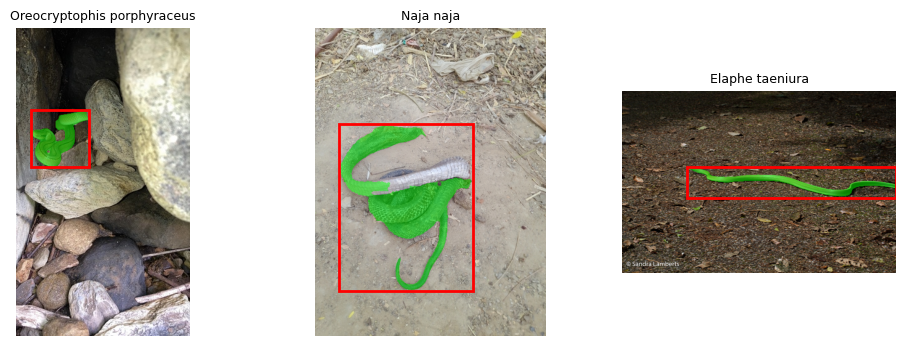

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, i in zip(axes, np.random.default_rng(42).choice(len(seg_frame), 3, replace=False)):
    row = seg_frame.iloc[i]
    rgb = load_rgb(row["image_file"])
    mask = load_mask(row["mask_file"], rgb.shape[:2])
    on = np.zeros(rgb.shape[:2], bool) if mask is None else mask == 1
    shade = rgb.copy()
    shade[on] = (0.5 * shade[on] + 0.5 * np.array([0, 255, 0])).astype(np.uint8)
    ax.imshow(shade)
    boxes = det_frame.loc[det_frame["path"] == row["path"], "snake_boxes"]
    for x1, y1, x2, y2 in (boxes.iloc[0] if len(boxes) else []):
        ax.add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, ec="red", lw=2))
    ax.set_title(row["species"], fontsize=9)
    ax.axis("off")
plt.show()

## 2. Train the four segmenters

All four see the same photos, the same 15 epochs, 320-pixel input and a light version of the augmentation from the
preprocessing notebook (flips and a little jitter). The settings are below. We keep the last epoch, since there is no
validation set to choose from, and the starting weights are the usual ImageNet or COCO ones.

In [5]:
SEG = dict(epochs=15, batch=32, size=320, lr=1e-3, weight_decay=1e-4, aug_strength=0.25, seed=42)
DET = dict(epochs=20, batch=32, size=320, seed=42)  # the detector, same size and seed
KINDS = ["maskhead", "lraspp", "unet", "yolo26n-seg"]
print("segmenters:", SEG, "\ndetector:", DET)
warm_cache(list(seg_frame["image_file"]) + list(seg_frame["mask_file"])
           + list(det_frame["image_file"]))

segmenters: {'epochs': 15, 'batch': 32, 'size': 320, 'lr': 0.001, 'weight_decay': 0.0001, 'aug_strength': 0.25, 'seed': 42} 
detector: {'epochs': 20, 'batch': 32, 'size': 320, 'seed': 42}


{'files': 24000,
 'missing': 0,
 'seconds': 168.82819509000007,
 'mb': 1845.012642}

Three of the segmenters are plain PyTorch networks. Each takes a photo and returns one number per pixel: how likely
that pixel is snake.

In [6]:
class MaskHeadNet(nn.Module):
    """The mask head of our own model, on its own small MobileNetV4 encoder."""

    def __init__(self, pretrained=True):
        super().__init__()
        self.encoder, channels = build_encoder("mobilenetv4_conv_small", pretrained, SEG["size"])
        self.head = MaskHead(channels)

    def forward(self, images):
        return self.head(self.encoder(images), images.shape[-2:])


class OutputOnly(nn.Module):
    """torchvision's segmentation models return a dict; keep the "out" logits."""

    def __init__(self, model):
        super().__init__()
        self.model = model

    def forward(self, images):
        return self.model(images)["out"]


def build_net(kind, pretrained=True):
    if kind == "maskhead":
        return MaskHeadNet(pretrained)
    if kind == "lraspp":
        weights = MobileNet_V3_Large_Weights.IMAGENET1K_V1 if pretrained else None
        net = lraspp_mobilenet_v3_large(weights=None, weights_backbone=weights, num_classes=1)
        return OutputOnly(net)
    return smp.Unet("mobilenet_v2", encoder_weights="imagenet" if pretrained else None, classes=1)

Training uses a loss that rewards both getting each pixel right (binary cross-entropy) and overlapping the true
mask (Dice). The seeding helpers keep every run repeatable: each augmentation step gets its own random seed.

In [7]:
def dice_bce(logits, masks, valid):
    """Cross-entropy plus soft Dice per photo, averaged over the photos whose mask is real."""
    if not valid.any():
        return logits.sum() * 0
    logits, targets = logits[valid], masks[valid].to(logits.dtype)
    bce = nn.functional.binary_cross_entropy_with_logits(logits, targets, reduction="none")
    bce = bce.flatten(1).mean(1)
    probs, flat = torch.sigmoid(logits).flatten(1), targets.flatten(1)
    dice = 1 - (2 * (probs * flat).sum(1) + 1.0) / (probs.sum(1) + flat.sum(1) + 1.0)
    return (bce + dice).mean()


def seed_augmentation(dataset, seed):
    """Give each augmentation pipeline and each step its own seed."""
    parts = []

    def walk(node):
        parts.append(node)
        for child in node.transforms:
            walk(child) if isinstance(child, BaseCompose) else parts.append(child)

    for pipeline in dataset.augment.values():
        walk(pipeline)
    for part, s in zip(parts, np.random.SeedSequence(seed).generate_state(len(parts))):
        part.set_random_seed(int(s))


def init_worker(worker_id):
    info = torch.utils.data.get_worker_info()
    random.seed(info.seed)
    np.random.seed(info.seed % 2 ** 32)
    seed_augmentation(info.dataset, info.seed)
    cv2.setNumThreads(0)

In [8]:
def train_segmenter(kind, out_dir):
    """AdamW, one warm-up epoch then cosine decay, mixed precision; saves the last epoch."""
    started, out_dir = time.perf_counter(), Path(out_dir)
    out_dir.mkdir(parents=True, exist_ok=True)
    random.seed(SEG["seed"]); np.random.seed(SEG["seed"]); torch.manual_seed(SEG["seed"])
    torch.backends.cudnn.benchmark = True
    data = SnakeDataset(seg_frame.assign(tier="tier1"), train=True, mode="full", size=SEG["size"],
                        aug_strength=SEG["aug_strength"])
    seed_augmentation(data, SEG["seed"])
    loader = DataLoader(data, batch_size=SEG["batch"], shuffle=True, drop_last=True,
                        num_workers=WORKERS, pin_memory=True, worker_init_fn=init_worker,
                        persistent_workers=True,
                        generator=torch.Generator().manual_seed(SEG["seed"]))
    net = build_net(kind).to(DEVICE)
    optimizer = torch.optim.AdamW(net.parameters(), lr=SEG["lr"], weight_decay=SEG["weight_decay"])
    steps, warmup = SEG["epochs"] * len(loader), len(loader)
    cosine = lambda s: ((s + 1) / warmup if s < warmup
                        else 0.5 * (1 + np.cos(np.pi * (s - warmup) / max(1, steps - warmup))))
    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, cosine)
    scaler = torch.amp.GradScaler(DEVICE)
    losses = []
    for epoch in range(1, SEG["epochs"] + 1):
        net.train()
        epoch_start, epoch_loss = time.perf_counter(), []
        for batch in loader:
            images, masks, valid = (batch[k].to(DEVICE, non_blocking=True)
                                    for k in ("image", "mask", "mask_valid"))
            with torch.autocast(DEVICE, dtype=torch.float16):
                logits = net(images)
            loss = dice_bce(logits.float(), masks, valid)
            optimizer.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(net.parameters(), 5.0)
            scaler.step(optimizer); scaler.update(); scheduler.step()
            epoch_loss.append(float(loss.detach()))
        losses.append(float(np.mean(epoch_loss)))
        seconds = time.perf_counter() - epoch_start
        print(f"{kind} epoch {epoch}/{SEG['epochs']}: loss {losses[-1]:.4f}, {seconds:.0f} s")
    torch.save(net.state_dict(), out_dir / "segmenter.pt")
    run = dict(kind=kind, weights="segmenter.pt", train_photos=len(seg_frame), epoch_loss=losses,
               parameters=sum(p.numel() for p in net.parameters()),
               seconds=time.perf_counter() - started, **SEG)
    (out_dir / "run.json").write_text(json.dumps(run))

maskhead epoch 1/15: loss 0.9649, 96 s
maskhead epoch 2/15: loss 0.5578, 72 s
maskhead epoch 3/15: loss 0.4822, 73 s
maskhead epoch 4/15: loss 0.4400, 73 s
maskhead epoch 5/15: loss 0.4144, 73 s
maskhead epoch 6/15: loss 0.3946, 72 s
maskhead epoch 7/15: loss 0.3666, 72 s
maskhead epoch 8/15: loss 0.3490, 73 s
maskhead epoch 9/15: loss 0.3309, 73 s
maskhead epoch 10/15: loss 0.3111, 72 s
maskhead epoch 11/15: loss 0.2971, 73 s
maskhead epoch 12/15: loss 0.2834, 73 s
maskhead epoch 13/15: loss 0.2728, 73 s
maskhead epoch 14/15: loss 0.2653, 74 s
maskhead epoch 15/15: loss 0.2646, 74 s
Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-8738ca79.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_large-8738ca79.pth


100%|██████████| 21.1M/21.1M [00:00<00:00, 157MB/s]


lraspp epoch 1/15: loss 0.8368, 91 s
lraspp epoch 2/15: loss 0.3925, 79 s
lraspp epoch 3/15: loss 0.3458, 78 s
lraspp epoch 4/15: loss 0.3211, 79 s
lraspp epoch 5/15: loss 0.3038, 78 s
lraspp epoch 6/15: loss 0.2904, 78 s
lraspp epoch 7/15: loss 0.2776, 78 s
lraspp epoch 8/15: loss 0.2682, 78 s
lraspp epoch 9/15: loss 0.2584, 78 s
lraspp epoch 10/15: loss 0.2482, 78 s
lraspp epoch 11/15: loss 0.2387, 79 s
lraspp epoch 12/15: loss 0.2331, 79 s
lraspp epoch 13/15: loss 0.2277, 79 s
lraspp epoch 14/15: loss 0.2245, 79 s
lraspp epoch 15/15: loss 0.2235, 79 s


unet epoch 1/15: loss 0.7608, 125 s
unet epoch 2/15: loss 0.3811, 111 s
unet epoch 3/15: loss 0.3360, 111 s
unet epoch 4/15: loss 0.3081, 111 s
unet epoch 5/15: loss 0.2907, 111 s
unet epoch 6/15: loss 0.2791, 111 s
unet epoch 7/15: loss 0.2651, 111 s
unet epoch 8/15: loss 0.2523, 111 s
unet epoch 9/15: loss 0.2390, 111 s
unet epoch 10/15: loss 0.2237, 111 s
unet epoch 11/15: loss 0.2132, 111 s
unet epoch 12/15: loss 0.2044, 111 s
unet epoch 13/15: loss 0.1965, 111 s
unet epoch 14/15: loss 0.1907, 112 s
unet epoch 15/15: loss 0.1892, 111 s


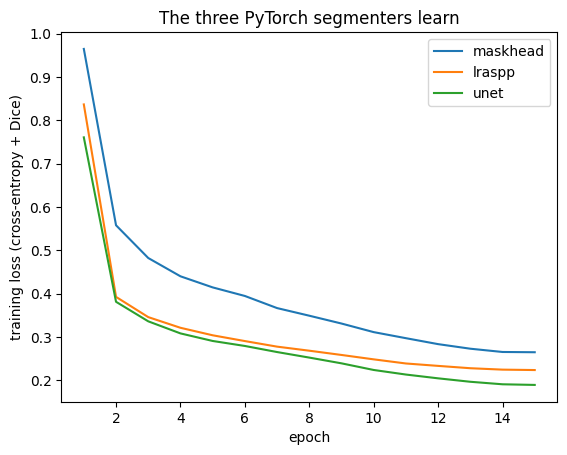

In [9]:
for kind in ["maskhead", "lraspp", "unet"]:
    if not (FRONT / "S1" / kind / "run.json").exists():  # finished models are not retrained
        train_segmenter(kind, FRONT / "S1" / kind)
read = lambda k: json.loads((FRONT / "S1" / k / "run.json").read_text())
runs = {k: read(k) for k in ["maskhead", "lraspp", "unet"]}
for kind, run in runs.items():
    plt.plot(range(1, SEG["epochs"] + 1), run["epoch_loss"], label=kind)
plt.xlabel("epoch"); plt.ylabel("training loss (cross-entropy + Dice)")
plt.title("The three PyTorch segmenters learn")
plt.legend(); plt.show()

## 3. Train the YOLO models

YOLO26n-seg (a segmenter) and YOLO26n (the detector) come from the `ultralytics` library, which wants its training
photos in folders with one label file each. For the segmenter a label is the outline of the SAM mask, on the same
320-pixel padded canvas the other three see. For the detector a label is a Grounding DINO box. We copy the first 64
training photos into a "val" folder only because the library insists on one; nothing is chosen with it.

In [10]:
def label_line(values):
    return " ".join(["0"] + [f"{v:.6f}" for v in values])


def mask_lines(mask):
    """One line per outer outline of a 0/1 mask, as fractions of the photo; specks dropped."""
    h, w = mask.shape
    outlines, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    return [label_line((o.reshape(-1, 2) / [w, h]).ravel()) for o in outlines
            if len(o) >= 3 and cv2.contourArea(o) >= 0.002 * mask.size]


def box_lines(boxes, w, h):
    """(centre x, centre y, width, height) as photo fractions, for finite boxes of 1 px or more."""
    lines = []
    for x1, y1, x2, y2 in boxes:
        x1, x2, y1, y2 = np.clip(x1, 0, w), np.clip(x2, 0, w), np.clip(y1, 0, h), np.clip(y2, 0, h)
        if np.isfinite([x1, y1, x2, y2]).all() and x2 - x1 >= 1 and y2 - y1 >= 1:
            lines.append(label_line([(x1 + x2) / 2 / w, (y1 + y2) / 2 / h,
                                     (x2 - x1) / w, (y2 - y1) / h]))
    return lines

Each photo is then written out with its label file, and the folder is described to YOLO in a small `data.yaml`.

In [11]:
def export_photo(row, root, size, boxes):
    rgb = load_rgb(row["image_file"])
    h, w = rgb.shape[:2]
    if boxes:
        lines = box_lines(row["snake_boxes"], w, h)
        scale = size / max(h, w)
        image = cv2.resize(rgb, (max(1, round(w * scale)), max(1, round(h * scale))),
                           interpolation=cv2.INTER_AREA if scale < 1 else cv2.INTER_LINEAR)
    else:
        mask = load_mask(row["mask_file"], rgb.shape[:2])
        if mask is None:
            return 0
        image, canvas_mask = apply_mode(rgb, mask, "full", None, size)
        lines = mask_lines(canvas_mask)
    if not lines:
        return 0
    stem = Path(row["path"]).with_suffix("").as_posix().replace("/", "__")
    Image.fromarray(image).save(root / "images/train" / f"{stem}.jpg", quality=95)
    (root / "labels/train" / f"{stem}.txt").write_text("\n".join(lines) + "\n")
    return 1


def write_yolo_set(frame, root, size, boxes):
    shutil.rmtree(root, ignore_errors=True)
    for kind in ("images", "labels"):
        for split in ("train", "val"):
            (root / kind / split).mkdir(parents=True)
    with ThreadPoolExecutor(WORKERS) as pool:
        rows = frame.to_dict("records")
        written = sum(pool.map(lambda row: export_photo(row, root, size, boxes), rows))
    for image in sorted((root / "images/train").glob("*.jpg"))[:64]:
        shutil.copy(image, root / "images/val" / image.name)
        label = f"{image.stem}.txt"
        shutil.copy(root / "labels/train" / label, root / "labels/val" / label)
    spec = {"path": str(root.resolve()), "train": "images/train", "val": "images/val",
            "names": {0: "snake"}}
    (root / "data.yaml").write_text(yaml.safe_dump(spec))
    return written

The training settings are the same for both YOLO models and match the PyTorch segmenters: AdamW, one warm-up epoch
then cosine decay, flips and the same light jitter (the ranges below are the preprocessing notebook's, times 0.25),
and no mosaic or mixup, so every batch is one optimizer step.

In [12]:
A = SEG["aug_strength"]
YOLO_ARGS = dict(
    optimizer="AdamW", lr0=1e-3, lrf=0.0, cos_lr=True, weight_decay=1e-4, warmup_epochs=1,
    deterministic=True, plots=False, pretrained=True, exist_ok=True, name="yolo",
    fliplr=0.5, flipud=0.2, degrees=25 * A, translate=0.05 * A, scale=0.12 * A,
    hsv_h=0.04 * A, hsv_s=0.2 * A, hsv_v=0.2 * A,
    shear=0.0, perspective=0.0, mosaic=0.0, close_mosaic=0, mixup=0.0, cutmix=0.0, copy_paste=0.0)


def train_yolo(name, start, frame, out_dir, settings, boxes, weights_file):
    """Export the photos, fine-tune `start`, keep the last epoch's weights and write run.json."""
    started, out_dir = time.perf_counter(), Path(out_dir)
    root = TMP / "yolo_sets" / name
    photos = write_yolo_set(frame, root, settings["size"], boxes)
    YOLO(start).train(data=str(root / "data.yaml"), epochs=settings["epochs"],
                      imgsz=settings["size"], batch=settings["batch"], nbs=settings["batch"],
                      seed=settings["seed"], workers=WORKERS, device=0,
                      project=str(out_dir.resolve()), **YOLO_ARGS)
    last = out_dir / "yolo/weights/last.pt"
    shutil.copy(last, out_dir / weights_file)
    params = sum(p.numel() for p in YOLO(str(last)).model.parameters())
    run = dict(kind=name, weights=weights_file, parameters=params, train_photos=photos,
               seconds=time.perf_counter() - started, **settings)
    (out_dir / "run.json").write_text(json.dumps(run))
    print(f"{name}: {photos:,} photos, {run['seconds'] / 60:.0f} min")


if not (FRONT / "S1/yolo26n-seg/run.json").exists():
    train_yolo("yolo26n-seg", "yolo26n-seg.pt", seg_frame, FRONT / "S1/yolo26n-seg", SEG,
               False, "segmenter.pt")
if not (FRONT / "D1/yolo26n-ft/run.json").exists():
    train_yolo("yolo26n-ft", "yolo26n.pt", det_frame, FRONT / "D1/yolo26n-ft", DET,
               True, "detector.pt")

yolo26n-seg: 10,002 photos, 19 min
yolo26n-ft: 13,501 photos, 18 min


## 4. Score them on photos people outlined by hand

The 284 Open Images photos were not used for training anywhere, and their outlines and boxes were drawn by people,
not by another model, so they are the honest test. Photos are read the same way the pipeline reads them (exposure
fix, no extra rotation). Open Images tags three photos as rotated; their masks are scored as stored. As a safety
check we also list any photo whose masks fit the photo turned on its side instead of as we read it.

In [13]:
oi_masks = pd.read_csv(EXTENDED / "open_images_snake_masks.csv")
oi_boxes = pd.read_csv(EXTENDED / "open_images_snake_boxes.csv")
oi = (oi_masks.sort_values(["image_id", "mask_file"]).groupby("image_id")
      .agg(image_file=("image_file", "first"), mask_files=("mask_file", list)).reset_index())
oi["image_file"] = [str(EXTENDED / f) for f in oi["image_file"]]
oi["mask_files"] = [[str(EXTENDED / f) for f in files] for files in oi["mask_files"]]
corners = ["XMin", "YMin", "XMax", "YMax"]
truth = {i: g[corners].to_numpy(float) for i, g in oi_boxes.groupby("ImageID")}
assert set(truth) <= set(oi["image_id"]), "a boxed photo has no mask row"
oi["boxes"] = [truth.get(i, np.zeros((0, 4))) for i in oi["image_id"]]

turned = []
for image_id, image_file, mask_files in zip(oi["image_id"], oi["image_file"], oi["mask_files"]):
    w, h = Image.open(image_file).size
    for mask_file in mask_files:
        mw, mh = Image.open(mask_file).size
        if w != h and abs(mw / mh - h / w) < abs(mw / mh - w / h):
            turned.append(image_id)
            break
rotated = oi_masks.loc[oi_masks["rotation"].fillna(0).ne(0), "image_id"].nunique()
n_boxes = int(sum(len(b) for b in oi["boxes"]))
print(f"{len(oi)} photos, {n_boxes} human boxes, {rotated} tagged as rotated,",
      f"{len(turned)} whose masks fit the photo turned")

284 photos, 298 human boxes, 3 tagged as rotated, 0 whose masks fit the photo turned


We also score the segmenters on 1,000 calibration photos against their SAM masks. These photos belong to nobody's
training set, but SAM is not a person, so this number says how well a segmenter copies SAM, not how good it is.

In [14]:
train_meta = metadata[metadata["split"] == "train"]
unused = (~train_meta["path"].isin(subset["path"])
          & ~train_meta["observer_id"].isin(subset["observer_id"]))
calibration = train_meta[unused]
calib = with_files(build_frame(calibration, classes, ["train"], mask_stats, masks_root=MASKS), DATA)
calib = calib[calib["mask_valid"]].reset_index(drop=True)

holdout = []
for i in np.random.default_rng(42).permutation(len(calib)):
    if len(holdout) == 1000:
        break
    w, h = Image.open(calib.at[i, "mask_file"]).size
    if load_mask(calib.at[i, "mask_file"], (h, w)) is not None:
        holdout.append(i)
holdout = calib.iloc[holdout].reset_index(drop=True)
print(f"{len(holdout)} holdout photos with a usable SAM mask")

1000 holdout photos with a usable SAM mask


A segmenter object hides the difference between the three PyTorch networks and YOLO. Given RGB photos it returns a 0/1
mask per photo at the photo's own size: the photo is padded to a 320-pixel square, the model runs, and the answer is
cut back out of the padding and scaled up.

In [15]:
def unletterbox(canvas_map, width, height, size):
    scale = size / max(height, width)
    rw, rh = max(1, round(width * scale)), max(1, round(height * scale))
    top, left = (size - rh) // 2, (size - rw) // 2
    window = np.asarray(canvas_map, dtype=np.float32)[top:top + rh, left:left + rw]
    return cv2.resize(window, (width, height), interpolation=cv2.INTER_LINEAR)


class Segmenter:
    """A trained segmenter: masks(photos) gives a 0/1 uint8 mask per RGB photo, at photo size."""

    def __init__(self, kind, folder):
        self.kind, self.size = kind, SEG["size"]
        if kind == "yolo26n-seg":
            self.net = YOLO(str(Path(folder) / "segmenter.pt"))
        else:
            self.net = build_net(kind, pretrained=False)
            self.net.load_state_dict(torch.load(Path(folder) / "segmenter.pt", weights_only=True))
            self.net.to(DEVICE).eval()

    def probabilities(self, canvases):
        if self.kind == "yolo26n-seg":  # the union of the instances YOLO keeps at confidence 0.25
            bgr = [cv2.cvtColor(c, cv2.COLOR_RGB2BGR) for c in canvases]
            found = self.net.predict(bgr, imgsz=self.size, conf=0.25, retina_masks=True,
                                     verbose=False, device=0)
            union = np.zeros((len(canvases), self.size, self.size), np.float32)
            for i, result in enumerate(found):
                if result.masks is not None and len(result.masks.data):
                    union[i] = result.masks.data.float().amax(dim=0).cpu().numpy()
            return union
        images = torch.stack([AUGMENT["eval"](image=c)["image"] for c in canvases]).to(DEVICE)
        with torch.inference_mode(), torch.autocast(DEVICE, dtype=torch.float16):
            return torch.sigmoid(self.net(images).float())[:, 0].cpu().numpy()

    def masks(self, photos, threshold=0.5):
        canvases = [apply_mode(p, None, "full", None, self.size)[0] for p in photos]
        return [(unletterbox(prob, p.shape[1], p.shape[0], self.size) > threshold).astype(np.uint8)
                for prob, p in zip(self.probabilities(canvases), photos)]

For each photo we measure overlap with the true mask two ways. IoU is the area both masks cover divided by the area
either covers; Dice is similar but counts the overlap twice. "Cleaned" means we first run the prediction through the
same cleanup the later notebooks use (close small gaps, drop specks, call a tiny mask empty), because that is what the
classifier actually receives.

In [16]:
class Scored(Dataset):
    """(photo, target mask) pairs; target_of(files, shape) builds the target."""

    def __init__(self, image_files, mask_files, target_of):
        self.items, self.target_of = list(zip(image_files, mask_files)), target_of

    def __len__(self):
        return len(self.items)

    def __getitem__(self, i):
        rgb = load_rgb(self.items[i][0])
        return rgb, self.target_of(self.items[i][1], rgb.shape[:2])


def human_target(files, shape):
    """All of a photo's human masks joined, each resized to the photo."""
    target = np.zeros(shape, np.uint8)
    for file in files:
        mask = np.asarray(Image.open(file).convert("L"), np.uint8)
        resized = cv2.resize(mask, shape[::-1], interpolation=cv2.INTER_NEAREST)
        target |= (resized > 127).astype(np.uint8)
    return target


def sam_target(files, shape):
    return load_mask(files[0], shape)


def overlap(pred, true):
    p, t = pred.astype(bool), true.astype(bool)
    both, either = (p & t).sum(), (p | t).sum()
    return (both / either if either else 1.0), (2 * both / (p.sum() + t.sum()) if either else 1.0)


def score_segmenter(seg, image_files, mask_files, target_of):
    """Per-photo IoU and Dice, raw and cleaned (a mask that cleaning empties counts as empty)."""
    per_photo = {"iou": [], "dice": [], "iou_cleaned": [], "dice_cleaned": []}
    loader = DataLoader(Scored(image_files, mask_files, target_of), batch_size=16,
                        num_workers=WORKERS, collate_fn=list)
    for batch in loader:
        photos, targets = zip(*batch)
        for mask, target in zip(seg.masks(list(photos)), targets):
            cleaned = clean_mask(mask)
            cleaned = np.zeros_like(mask) if cleaned is None else cleaned
            for suffix, pred in (("", mask), ("_cleaned", cleaned)):
                iou, dice = overlap(pred, target)
                per_photo["iou" + suffix].append(iou)
                per_photo["dice" + suffix].append(dice)
    return {**{k: float(np.mean(v)) for k, v in per_photo.items()}, "per_photo": per_photo}

In [17]:
rows, oi_scores = [], {}
for kind in KINDS:
    run = json.loads((FRONT / "S1" / kind / "run.json").read_text())
    seg = Segmenter(kind, FRONT / "S1" / kind)
    human = score_segmenter(seg, oi["image_file"], oi["mask_files"], human_target)
    sam = score_segmenter(seg, holdout["image_file"], [[f] for f in holdout["mask_file"]],
                          sam_target)
    oi_scores[kind] = human["per_photo"]["iou_cleaned"]
    rows.append({"segmenter": kind, "parameters (M)": run["parameters"] / 1e6,
                 "IoU": human["iou_cleaned"], "IoU raw": human["iou"],
                 "Dice": human["dice_cleaned"],
                 "copies SAM (IoU)": sam["iou_cleaned"], "train minutes": run["seconds"] / 60})
    del seg; torch.cuda.empty_cache()
seg_table = pd.DataFrame(rows).set_index("segmenter")
print("Segmenters on the 284 Open Images photos (human outlines); last column is training time")
seg_table.round(3)

Segmenters on the 284 Open Images photos (human outlines); last column is training time


,parameters (M),IoU,IoU raw,Dice,copies SAM (IoU),train minutes
segmenter,,,,,,
maskhead,1.364,0.768,0.768,0.856,0.687,18.623
lraspp,3.218,0.778,0.782,0.860,0.707,19.869
unet,6.629,0.840,0.840,0.904,0.796,28.070
yolo26n-seg,3.083,0.808,0.808,0.881,0.754,19.420


The detectors are scored differently, since they draw boxes. A predicted box counts as right when it overlaps a human
box by at least half (IoU 0.5). Precision is the share of boxes above confidence 0.25 that were right; recall is the
share of human boxes found; mAP@0.5 summarises the whole trade-off over every confidence level. We compare our
fine-tuned YOLO26n with an off-the-shelf detector (`yolov8n-oiv7`, trained on all of Open Images) as the baseline.

In [18]:
def snake_boxes(model, bgr_photos, conf, normalized=False, batch=16):
    """Per photo, its snake boxes as [x1, y1, x2, y2, score], in pixels or photo fractions."""
    names = model.names if isinstance(model.names, dict) else dict(enumerate(model.names))
    snake = [i for i, name in names.items() if str(name).strip().lower() == "snake"]
    assert len(snake) == 1, "the detector must have exactly one snake class"
    found = []
    for start in range(0, len(bgr_photos), batch):
        chunk = bgr_photos[start:start + batch]
        # rect=False pads every call alike, as the training boxes were
        for result in model.predict(chunk, conf=conf, verbose=False, classes=snake, rect=False):
            b = result.boxes
            corners = (b.xyxyn if normalized else b.xyxy).cpu().numpy()
            found.append(np.column_stack([corners, b.conf.cpu().numpy()]).reshape(-1, 5).tolist())
    return found


def score_detector(model):
    boxes = []
    for start in range(0, len(oi), 32):
        files = oi["image_file"][start:start + 32]
        photos = [cv2.cvtColor(load_rgb(f), cv2.COLOR_RGB2BGR) for f in files]
        boxes += snake_boxes(model, photos, conf=0.001, normalized=True)  # keep everything, for mAP
    sure = [[b for b in found if b[4] >= 0.25] for found in boxes]
    at_conf, everything = det_scores(sure, list(oi["boxes"])), det_scores(boxes, list(oi["boxes"]))
    return {"precision @0.25": at_conf["precision"], "recall @0.25": at_conf["recall"],
            "mAP@0.5": everything["map50"]}


detectors = {"yolov8n-oiv7": ("off the shelf", "yolov8n-oiv7.pt"),
             "yolo26n-ft": ("fine-tuned on our boxes", str(FRONT / "D1/yolo26n-ft/detector.pt"))}
rows = []
for name, (what, weights) in detectors.items():
    model = YOLO(weights)
    params = sum(p.numel() for p in model.model.parameters()) / 1e6
    rows.append({"detector": name, "what": what, "parameters (M)": params, **score_detector(model)})
det_table = pd.DataFrame(rows).set_index("detector")
det_table.round(3)

,what,parameters (M),precision @0.25,recall @0.25,mAP@0.5
detector,,,,,
yolov8n-oiv7,off the shelf,3.498,0.823,0.218,0.514
yolo26n-ft,fine-tuned on our boxes,2.534,0.873,0.926,0.938


## 5. The winners

For the segmenters the best IoU on the human outlines wins, but IoUs within 0.005 of the best count as a tie and the
smaller model takes it. For the detectors the best mAP@0.5 wins. These are the models that make the boxes and masks
for the rest of the project.

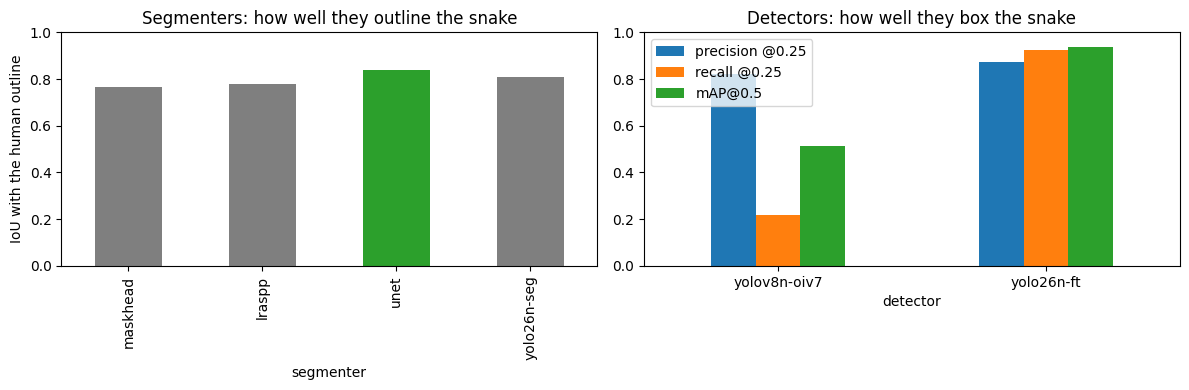

segmenter winner: unet; detector winner: yolo26n-ft


In [19]:
best = seg_table["IoU"].max()
tied = seg_table[seg_table["IoU"] >= best - 0.005 - 1e-9]
seg_winner = tied["parameters (M)"].idxmin()
det_winner = det_table["mAP@0.5"].idxmax()
seg_table.assign(winner=seg_table.index == seg_winner).to_csv(FRONT / "S1_table.csv")
det_table.assign(winner=det_table.index == det_winner).to_csv(FRONT / "D1_table.csv")
(FRONT / "winners.json").write_text(json.dumps({"segmenter": seg_winner, "detector": det_winner}))

fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4))
colors = ["tab:green" if k == seg_winner else "tab:gray" for k in seg_table.index]
seg_table["IoU"].plot.bar(ax=left, color=colors)
left.set_ylim(0, 1); left.set_ylabel("IoU with the human outline")
left.set_title("Segmenters: how well they outline the snake")
det_table[["precision @0.25", "recall @0.25", "mAP@0.5"]].plot.bar(ax=right)
right.set_ylim(0, 1); right.set_title("Detectors: how well they box the snake")
right.tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()
print(f"segmenter winner: {seg_winner}; detector winner: {det_winner}")

Three photos show what the numbers mean: the segmenter's worst, median and best photo on the Open Images test.
Left column of each pair: the winning detector's box (red) against the human box (white). Right: the winning
segmenter's mask in green.

Every photo is Creative Commons; its licence and photographer credit are in the dataset's tables under its id.


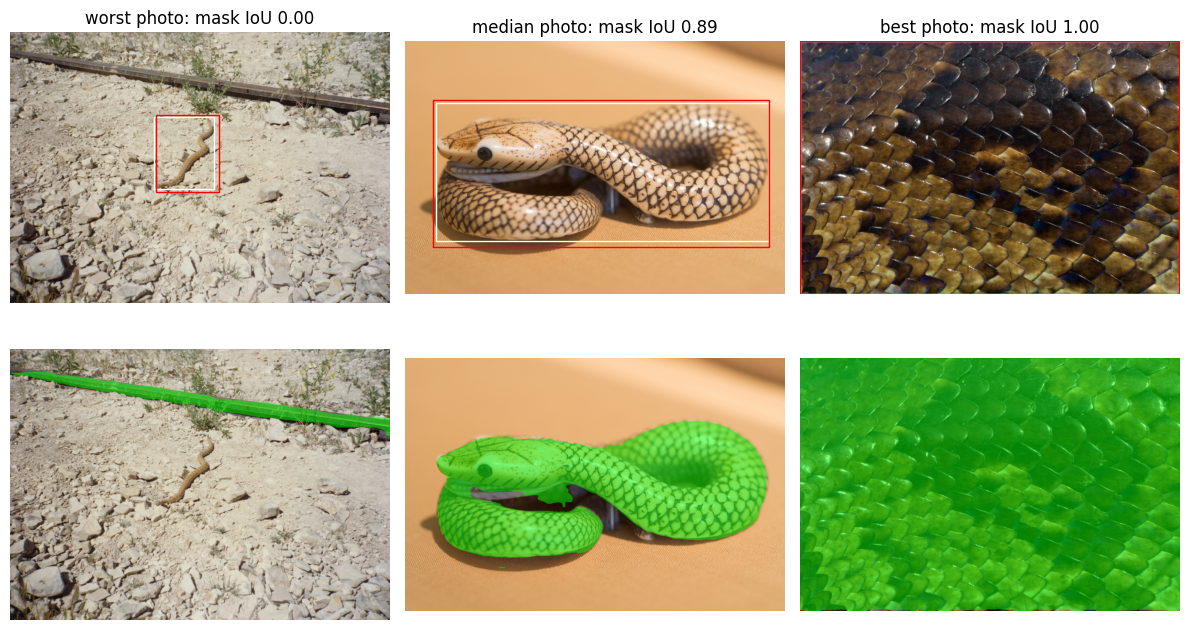

In [20]:
seg = Segmenter(seg_winner, FRONT / "S1" / seg_winner)
detector = YOLO(detectors[det_winner][1])
order = np.argsort(oi_scores[seg_winner])
picks = [order[0], order[len(order) // 2], order[-1]]
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for col, (i, label) in enumerate(zip(picks, ["worst", "median", "best"])):
    rgb = load_rgb(oi.at[i, "image_file"])
    found = snake_boxes(detector, [cv2.cvtColor(rgb, cv2.COLOR_RGB2BGR)], conf=0.05)[0]
    box = max(found, key=lambda b: b[4], default=None)
    axes[0, col].imshow(rgb)
    h, w = rgb.shape[:2]
    for x1, y1, x2, y2 in oi.at[i, "boxes"] * [w, h, w, h]:
        axes[0, col].add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, ec="white"))
    if box:
        axes[0, col].add_patch(plt.Rectangle(box[:2], box[2] - box[0], box[3] - box[1],
                                             fill=False, ec="red"))
    shade = rgb.copy()
    on = seg.masks([rgb])[0] == 1
    shade[on] = (0.5 * shade[on] + 0.5 * np.array([0, 255, 0])).astype(np.uint8)
    axes[1, col].imshow(shade)
    axes[0, col].set_title(f"{label} photo: mask IoU {oi_scores[seg_winner][i]:.2f}")
    for ax in axes[:, col]:
        ax.axis("off")
plt.tight_layout(); plt.show()

## 6. Write the boxes and masks for every photo

The later notebooks never run these models. They read `frontend_preds.csv`, one row per photo with four columns: the
photo's `path`, its `box` as `[x1, y1, x2, y2]` in pixels, the `mask_file` (a PNG saved under `masks_pred/`) and the
detector's `box_conf`. Boxes and masks are left empty where the model finds nothing. The box is the detector's most
confident one at 0.05 or above; the classifier later learns its own "no snake found" cut-off from `box_conf`. A
mask is saved only if the cleanup above keeps it. The photos are the experiment subset, every validation photo, the
calibration photos and one half of the unknown-species pool.

In [21]:
unknown = metadata[metadata["split"] == "unknown_pool"]
listed = set(unknown.loc[unknown["who_category"].astype(str) != "not_listed", "species"])
others = sorted(set(unknown["species"]) - listed)
half = np.random.default_rng(42).permutation(others)[:len(others) // 2]
sets = {"train": train_rows, "val": metadata[metadata["split"] == "val"],
        "calibration": calibration,
        "unknown": unknown[unknown["species"].isin(listed | set(half))]}  # unknown half A
photos = pd.concat([rows[["path"]].assign(frame=name) for name, rows in sets.items()])
photos = photos.drop_duplicates("path").reset_index(drop=True)
photos["image_file"] = [str(DATA / "data" / p) for p in photos["path"]]
print(photos["frame"].value_counts().to_string(), f"\n{len(photos):,} photos in all")

frame
val            17151
train          13925
calibration     7999
unknown          451 
39,526 photos in all


In [22]:
class Photos(Dataset):
    def __len__(self):
        return len(photos)

    def __getitem__(self, i):
        return i, load_rgb(photos.at[i, "image_file"])


boxes, confs, mask_files = [""] * len(photos), [""] * len(photos), [""] * len(photos)
conf_values = np.full(len(photos), np.nan)
for batch in DataLoader(Photos(), batch_size=32, num_workers=WORKERS, collate_fn=list):
    indices, rgbs = zip(*batch)
    found = snake_boxes(detector, [cv2.cvtColor(r, cv2.COLOR_RGB2BGR) for r in rgbs], conf=0.05)
    for i, mask, candidates in zip(indices, seg.masks(list(rgbs)), found):
        if candidates:
            *box, conf_values[i] = max(candidates, key=lambda b: b[4])
            boxes[i], confs[i] = json.dumps([round(v, 2) for v in box]), f"{conf_values[i]:.4f}"
        if clean_mask(mask) is not None:
            target = PREDS / "masks_pred" / Path(photos.at[i, "path"]).with_suffix(".png")
            target.parent.mkdir(parents=True, exist_ok=True)
            assert cv2.imwrite(str(target), mask * 255), f"could not write {target}"
            mask_files[i] = target.relative_to(PREDS).as_posix()
preds = pd.DataFrame({"path": photos["path"], "box": boxes, "mask_file": mask_files,
                      "box_conf": confs})
preds.to_csv(PREDS / "frontend_preds.csv", index=False)
found = photos.assign(box=preds["box"].ne(""), box_at_0_25=conf_values >= 0.25,
                      mask=preds["mask_file"].ne(""))
coverage = found.groupby("frame", sort=False)[["box", "box_at_0_25", "mask"]].mean()
summary = {"photos": len(preds), "box_floor": 0.05, "coverage": coverage.to_dict("index"),
           "segmenter": seg_winner, "detector": det_winner}
(PREDS / "summary.json").write_text(json.dumps(summary))
print("Share of photos with a box (confidence 0.05+), a box at 0.25+, and a usable mask:")
coverage.round(3)

Share of photos with a box (confidence 0.05+), a box at 0.25+, and a usable mask:


,box,box_at_0_25,mask
frame,,,
train,0.999,0.937,0.923
val,0.999,0.925,0.926
calibration,0.999,0.923,0.877
unknown,1.000,0.960,0.962


A bulk write that exits quietly can still be wrong, so we read the file back the way the next notebooks do. We check
that every photo has exactly one row, that 20 random masks load at their photo's size, that 20 random boxes lie inside
their photos, and that no box is missing its confidence or sits under the 0.05 floor. As a control, a mask loaded at the
wrong size must be refused; if it is not, the size check itself is broken.

In [23]:
check = pd.read_csv(PREDS / "frontend_preds.csv", keep_default_na=False)
assert sorted(check["path"]) == sorted(photos["path"]), "rows don't match the photos"
assert check["path"].is_unique
assert check["box"].eq("").equals(check["box_conf"].eq("")), "a box without its confidence"
has_box = check["box"].ne("")
assert pd.to_numeric(check.loc[has_box, "box_conf"]).ge(0.05).all(), "a box under the floor"
files = photos.set_index("path")["image_file"]
with_mask = check[check["mask_file"].ne("")].sample(20, random_state=42)
for path, mask_file in with_mask[["path", "mask_file"]].values:
    shape = load_rgb(files[path]).shape[:2]
    assert load_mask(str(PREDS / mask_file), shape) is not None, f"{mask_file} fails load_mask"
    if shape[0] != shape[1]:
        try:
            load_mask(str(PREDS / mask_file), shape[::-1])
            raise AssertionError("the wrong-size control was accepted")
        except ValueError:
            pass
for path, box in check[has_box].sample(20, random_state=42)[["path", "box"]].values:
    h, w = load_rgb(files[path]).shape[:2]
    x1, y1, x2, y2 = json.loads(box)
    assert 0 <= x1 < x2 <= w + 1 and 0 <= y1 < y2 <= h + 1, f"box {box} is outside {path}"
print(f"{len(check):,} rows, one per photo; 20 masks and 20 boxes checked;",
      "the wrong-size control failed as it should")

39,526 rows, one per photo; 20 masks and 20 boxes checked; the wrong-size control failed as it should


## 7. Does cropping help the classifier?

The training notebook trained the species classifier once per way of showing it the photo. All runs use the same
photos, model and settings; only the input changes. The tables below are read from those saved runs, not retrained
here (a fresh run can differ by about 0.005). The runs: the whole photo (our starting point); a crop to the detector's box; a crop to the box around the mask;
the photo with its background dimmed or greyed out using the mask; and two runs that teach the model the mask as an
extra task without feeding it the mask. Photos with no box or mask are shown whole.

In [24]:
SUMMARY = (SRC.parent if SRC.exists() else REPO) / "results/m3/summary"
runs = pd.read_csv(SUMMARY / "model_runs.csv")
names = {"R_F0": "whole photo", "FE_F1": "crop to the detector's box",
         "FE_F1m": "crop to the mask's box", "FE_F2": "dim the background",
         "FE_F3": "grey out the background", "FE_F4": "learn the mask, don't use it",
         "FE_F5": "learn the mask, pool with it"}
fe = runs[runs["run"].isin(names)].set_index("run").loc[list(names)]
fe.index = [names[r] for r in fe.index]
fe = fe.rename(columns={"WHO recall (O2 raw)": "WHO-listed species recall",
                        "val prediction coverage": "photos with a box or mask"})
fe["gain over whole photo"] = fe["macro-F1 head"] - fe.loc["whole photo", "macro-F1 head"]
show = ["macro-F1 head", "gain over whole photo", "top-1", "WHO-listed species recall",
        "photos with a box or mask"]
fe[show].round(3)

,macro-F1 head,gain over whole photo,top-1,WHO-listed species recall,photos with a box or mask
whole photo,0.257,0.000,0.531,0.736,NaN
crop to the detector's box,0.311,0.053,0.583,0.758,1.000
crop to the mask's box,0.312,0.055,0.583,0.763,0.932
dim the background,0.291,0.033,0.563,0.750,0.932
grey out the background,0.259,0.001,0.532,0.740,0.932
"learn the mask, don't use it",0.250,-0.007,0.530,0.732,NaN
"learn the mask, pool with it",0.259,0.001,0.532,0.727,NaN


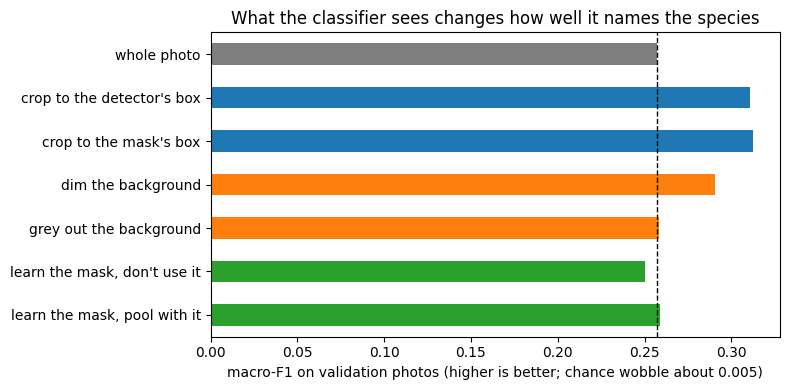

In [25]:
colors = ["tab:gray"] + ["tab:blue"] * 2 + ["tab:orange"] * 2 + ["tab:green"] * 2
fe["macro-F1 head"].plot.barh(color=colors, figsize=(8, 4))
plt.axvline(fe.loc["whole photo", "macro-F1 head"], color="k", ls="--", lw=1)
plt.xlabel("macro-F1 on validation photos (higher is better; chance wobble about 0.005)")
plt.title("What the classifier sees changes how well it names the species")
plt.gca().invert_yaxis(); plt.tight_layout(); plt.show()

## What we found

Finding the snake first is worth it, and a box is enough. Cropping to the detector's box lifts the classifier's
macro-F1 from about 0.26 on the whole photo to about 0.31, far more than the 0.005 by which repeat runs differ by
chance. Cropping to the box around the mask scores the same within that margin, so the extra mask adds nothing over
a box. Painting the background out with the mask does not beat the box crop: dimming gains a little, greying it out
gains nothing, and teaching the model the mask as a side task gains nothing either. Sections 4 and 5 name the best
segmenter and detector; we keep the detector's box crop as the front end.